# Session 12 lab: Which campaigns deserve the budget?

<p class="lead">
Build a campaign scorecard that adds up, find the rows where a rate cannot exist, catch a channel ranking that a small campaign has flipped, debug three broken ROAS analyses, and turn what you find into a controlled test the marketing lead can approve.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/12_marketing_campaigns_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

> *Marketing lead: "Next quarter's budget is fixed. I want to move some money towards the campaigns that work best, but I can only defend a change I can measure. Which campaigns deserve a **controlled budget change**, and how would we know if it worked?"*

Your job is to give her a scorecard she can trust, an honest reading of it, and **one** test proposal. Not a new budget split.

> **About the data**
>
> `marketing_daily.csv` is **synthetic** teaching data generated by the course: one row per **day of 2025 × paid campaign**, describing no real company, brand or platform. Money is in neutral **currency units**. Each purchase is credited to exactly one campaign on the same day; there is no touchpoint history and no organic traffic.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G4 |
| **Independent tasks** | Same skills, new questions, on your own or in pairs | I1–I4 |
| **Challenge** | Harder reasoning and debugging | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Check a campaign-day table's key, completeness and funnel order before computing any rate.
2. Compute CTR, conversion rate, CPC, CPA and ROAS as ratios of sums at any level, and reconcile them to the company total.
3. Treat zero denominators as "not available" and report review cases instead of hiding them.
4. Explain why the mean of campaign rates and the weighted rate rank channels differently.
5. Build a CPA and ROAS scorecard that keeps volumes visible.
6. Separate attributed revenue from incremental revenue, and propose a controlled test with a success metric and guardrails.

**Evidence you keep:** your campaign scorecard, a short explanation of the weighted-rate result, and a test proposal.

---

## Before you start

- Read the [Session 12 lecture](12_marketing_campaigns_lecture.md).
- Re-read the weighted-rate part of the [Session 5 lecture](05_metrics_and_kpis_lecture.md) and the A/B test parts of the [Session 9 lecture](09_sampling_and_experiments_lecture.md).

---

## Guided practice

### G1 (Core): Load the table and check it

Run the three setup cells, then load the data.

In [1]:
# Marketing data setup (synthetic). Run this cell first.
# Downloads the course's synthetic marketing data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

MARKETING_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/marketing-v1/"
MARKETING_SHA256 = {
    "marketing_daily.csv": "1cbfc8e1c91ae72d18364b2d13bdf6db513c4aec28c339ef8b91f87a60dc0a07",
    "ab_test.csv": "41a3662997111b66d7ab1eb899f4b32e26bd64c66284ce881db6b8a7300ad47f",
}
MARKETING_DIR = os.environ.get("COURSE_MARKETING_DIR", "")


def load_marketing(name):
    """Load one marketing-v1 file: 'marketing_daily.csv' or 'ab_test.csv'."""
    if MARKETING_DIR:
        with open(os.path.join(MARKETING_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(MARKETING_URL + name).read()
    if hashlib.sha256(data).hexdigest() != MARKETING_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["date"])


print("Marketing setup complete.")

Marketing setup complete.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Plot style ready.")

Plot style ready.


In [3]:
COUNTS = ["spend", "impressions", "clicks", "sessions", "conversions", "attributed_revenue"]


def safe_div(numerator, denominator):
    """numerator / denominator, left blank (NaN) wherever the denominator is 0."""
    return numerator / denominator.where(denominator != 0)


def add_rates(totals):
    """Add the five funnel rates to a table of SUMMED counts (ratios of sums)."""
    t = totals.copy()
    t["CTR"] = safe_div(t["clicks"], t["impressions"])
    t["conv_rate"] = safe_div(t["conversions"], t["sessions"])
    t["CPC"] = safe_div(t["spend"], t["clicks"])
    t["CPA"] = safe_div(t["spend"], t["conversions"])
    t["ROAS"] = safe_div(t["attributed_revenue"], t["spend"])
    return t


def show(table):
    """Format a totals table for reading. Blank rates show as 'n/a' (not available)."""
    out = table.copy()
    for col in out.columns:
        if col in ("CTR", "conv_rate", "share of spend", "share of conversions"):
            out[col] = out[col].map(lambda v: "n/a" if pd.isna(v) else f"{v:.2%}")
        elif col in ("spend", "attributed_revenue", "CPC", "CPA", "ROAS"):
            out[col] = out[col].map(lambda v: "n/a" if pd.isna(v) else f"{v:,.2f}")
        elif pd.api.types.is_numeric_dtype(out[col]):
            out[col] = out[col].map(lambda v: "n/a" if pd.isna(v) else f"{v:,.0f}")
    return out


print("Helpers ready: safe_div, add_rates, show.")

Helpers ready: safe_div, add_rates, show.


In [4]:
daily = load_marketing("marketing_daily.csv")
print("Rows:", len(daily), "| columns:", list(daily.columns))
daily.head()

Rows: 2555 | columns: ['date', 'campaign_id', 'campaign_name', 'channel', 'spend', 'impressions', 'clicks', 'sessions', 'conversions', 'attributed_revenue']


,date,campaign_id,campaign_name,channel,spend,impressions,clicks,sessions,conversions,attributed_revenue
0,2025-01-01,DISP-01,Display - partner sites,Display,575.20,175974,633,449,2,150.53
1,2025-01-01,EML-01,Email - newsletter,Email,45.78,74237,563,536,16,"1,403.35"
2,2025-01-01,SOC-01,Social - broad audience,Social,998.65,135199,1651,1301,12,946.74
3,2025-01-01,SOC-02,Social - past visitors,Social,60.57,6692,136,117,8,982.79
4,2025-01-01,SRCH-01,Search - product terms,Search,881.76,40050,1764,1643,52,"7,017.99"


Before any rate, check the structure. The table should have exactly one row for every day × campaign, and every row should respect the funnel: impressions ≥ clicks ≥ sessions ≥ conversions ≥ 0.

> **Your turn:** change the code in the next cell and run it again.

In [5]:
# 1. Run the cell. Are all checks passing?
# 2. Change the funnel check to compare clicks with impressions the WRONG way round (clicks >= impressions).
#    How many rows "fail"? Why does a check need to be written carefully?
# 3. Add a check that spend and attributed_revenue are never negative.
days, campaigns = daily["date"].nunique(), daily["campaign_id"].nunique()
print("Days:", days, "| campaigns:", campaigns, "| expected rows:", days * campaigns, "| actual:", len(daily))
print("Duplicate (date, campaign_id) keys:", daily.duplicated(["date", "campaign_id"]).sum())
print("Missing values:", daily.isna().sum().sum())

funnel_ok = (
    (daily["impressions"] >= daily["clicks"])
    & (daily["clicks"] >= daily["sessions"])
    & (daily["sessions"] >= daily["conversions"])
    & (daily["conversions"] >= 0)
)
print("Rows breaking the funnel order:", (~funnel_ok).sum())

Days: 365 | campaigns: 7 | expected rows: 2555 | actual: 2555
Duplicate (date, campaign_id) keys: 0
Missing values: 0
Rows breaking the funnel order: 0


### G2 (Core): Campaign totals as ratios of sums

`add_rates()` from the setup cell adds CTR, conversion rate, CPC, CPA and ROAS to a table of **summed** counts. So the pattern is always: **group, sum, then add rates**.

> **Your turn:** change the code in the next cell and run it again.

In [6]:
# 1. Run the cell. Which campaign has the most conversions? The lowest CPA? The highest ROAS?
# 2. Change group_by to ["channel"]. How many rows now?
# 3. Change group_by to [daily["date"].dt.month]. Which month had the highest ROAS?
group_by = ["channel", "campaign_id"]

totals = add_rates(daily.groupby(group_by)[COUNTS].sum())
show(totals)

spend impressions   clicks sessions conversions  \
channel campaign_id                                                         
Display DISP-01      207,555.98  63,293,507  257,369  179,711       1,518   
Email   EML-01        15,426.37  26,068,668  212,422  201,704       4,378   
Search  SRCH-01      362,654.08  16,140,471  738,763  679,463      24,629   
        SRCH-02      256,844.20  14,002,066  541,789  487,457      15,308   
Social  SOC-01       433,453.56  56,822,940  693,917  556,007       6,408   
        SOC-02        24,001.47   2,612,255   53,241   45,313       2,850   
Video   VID-01       169,989.92  15,139,599   92,623   69,547         748   

                    attributed_revenue    CTR conv_rate   CPC     CPA   ROAS  
channel campaign_id                                                           
Display DISP-01             132,218.98  0.41%     0.84%  0.81  136.73   0.64  
Email   EML-01              451,164.11  0.81%     2.17%  0.07    3.52  29.25  
Search  SRCH-01           2,897,731.90  4.58%     3.62%  0.49   14.72   7.99  
        SRCH-02           1,589,252.73  3.87%     3.14%  0.47   16.78   6.19  
Social  SOC-01              595,049.96  1.22%     1.15%  0.62   67.64   1.37  
        SOC-02              315,601.00  2.04%     6.29%  0.45    8.42  13.15  
Video   VID-01               68,082.75  0.61%     1.08%  1.84  227.26   0.40

### G3 (Core): Channel totals that reconcile

Build the channel totals and the company total, and check that both add up. A scorecard that does not reconcile to the company total is not ready to show anyone.

In [7]:
by_campaign = add_rates(daily.groupby(["channel", "campaign_id"])[COUNTS].sum())
by_channel = add_rates(daily.groupby("channel")[COUNTS].sum())
company = add_rates(daily[COUNTS].sum().to_frame("All campaigns").T)

for col in COUNTS:
    same = np.isclose(by_campaign[col].sum(), company[col].iloc[0]) and np.isclose(by_channel[col].sum(), company[col].iloc[0])
    print(f"{col:20s} campaigns and channels add up to the company total: {same}")

show(pd.concat([by_channel, company]))

spend                campaigns and channels add up to the company total: True
impressions          campaigns and channels add up to the company total: True
clicks               campaigns and channels add up to the company total: True
sessions             campaigns and channels add up to the company total: True
conversions          campaigns and channels add up to the company total: True
attributed_revenue   campaigns and channels add up to the company total: True


,spend,impressions,clicks,sessions,conversions,attributed_revenue,CTR,conv_rate,CPC,CPA,ROAS
Display,"207,555.98","63,293,507","257,369","179,711","1,518","132,218.98",0.41%,0.84%,0.81,136.73,0.64
Email,"15,426.37","26,068,668","212,422","201,704","4,378","451,164.11",0.81%,2.17%,0.07,3.52,29.25
Search,"619,498.28","30,142,537","1,280,552","1,166,920","39,937","4,486,984.63",4.25%,3.42%,0.48,15.51,7.24
Social,"457,455.03","59,435,195","747,158","601,320","9,258","910,650.96",1.26%,1.54%,0.61,49.41,1.99
Video,"169,989.92","15,139,599","92,623","69,547",748,"68,082.75",0.61%,1.08%,1.84,227.26,0.40
All campaigns,"1,469,925.58","194,079,506","2,590,124","2,219,202","55,839","6,049,101.43",1.33%,2.52%,0.57,26.32,4.12


> **What do you notice?**
>
> The counts and money in the "All campaigns" row are the sums of the rows above it. The **rates** in that row are **not** the sums or the averages of the rates above it: they are the company's own ratios of sums. Check one by hand: company CPA = total spend ÷ total conversions.

### G4 (Core): Zero denominators and review cases

Find every row where a rate has no denominator, then look at the **review cases**: days with conversions but no spend.

> **Your turn:** change the code in the next cell and run it again.

In [8]:
# 1. Run the cell. Which campaigns have spend = 0 days? Which ones have review cases?
# 2. Change condition to daily["conversions"] == 0. Which campaign has most days with no conversions? Why might that be?
# 3. Change condition to daily["clicks"] == 0. What rate is not available on those days?
condition = daily["spend"] == 0

print("Rows matching:", condition.sum())
print(daily.loc[condition, "campaign_id"].value_counts().to_string())

review = daily[(daily["spend"] == 0) & (daily["conversions"] > 0)]
print("\nReview cases (spend = 0 but conversions > 0):", len(review))
review[["date", "campaign_id", "spend", "sessions", "conversions", "attributed_revenue"]]

Rows matching: 39
campaign_id
EML-01     12
SOC-02      6
SRCH-02     6
SOC-01      5
SRCH-01     5
DISP-01     3
VID-01      2

Review cases (spend = 0 but conversions > 0): 12


,date,campaign_id,spend,sessions,conversions,attributed_revenue
666,2025-04-06,EML-01,0.00,452,6,466.08
883,2025-05-07,EML-01,0.00,477,7,601.93
932,2025-05-14,EML-01,0.00,538,10,920.63
1023,2025-05-27,EML-01,0.00,524,8,767.31
1128,2025-06-11,EML-01,0.00,526,15,"1,355.61"
1184,2025-06-19,EML-01,0.00,506,13,"1,471.54"
1457,2025-07-28,EML-01,0.00,467,12,"1,476.80"
1471,2025-07-30,EML-01,0.00,500,9,"1,026.26"
1870,2025-09-25,EML-01,0.00,485,13,"1,311.34"
1975,2025-10-10,EML-01,0.00,535,5,522.14


Decide, and write in your evidence log, how you treat these rows:

- [ ] **Paused days** (nothing shown, nothing spent): keep them; they add zeros to the totals and change nothing.
- [ ] **Review cases** (free Email sends with sales): keep them in the campaign totals, list them in a note, and give them **no** daily ROAS.
- [ ] **Days with no conversions**: daily CPA is "not available"; the campaign's total CPA still exists if it had conversions over the period.

---

## Independent tasks

### I1 (Core): The mean of campaign rates versus the weighted rate

A colleague built a "conversion rate by channel" slide by averaging each channel's campaign rates. Compare it with the weighted rate (ratio of sums).

> **Your turn:** change the code in the next cell and run it again.

In [9]:
# 1. Run the cell. For which channel do the two methods differ most? Does the channel ranking change?
# 2. Change rate to "CTR", then to "ROAS". Does the same channel cause the difference?
# 3. Look at the "sessions" column of by_campaign for that channel's campaigns. Explain the difference in two sentences.
rate = "conv_rate"

compare = pd.DataFrame({
    "campaigns": by_campaign.groupby("channel").size(),
    "mean of campaign rates": by_campaign[rate].groupby("channel").mean(),
    "weighted rate (sum ÷ sum)": by_channel[rate],
})
compare["rank by mean"] = compare["mean of campaign rates"].rank(ascending=False).astype(int)
compare["rank by weighted"] = compare["weighted rate (sum ÷ sum)"].rank(ascending=False).astype(int)
shown = compare.sort_values("rank by weighted")
as_text = "{:.2%}".format if rate in ("CTR", "conv_rate") else "{:,.2f}".format    # percent, or plain number for CPC/CPA/ROAS
for col in ["mean of campaign rates", "weighted rate (sum ÷ sum)"]:
    shown[col] = shown[col].map(as_text)
shown

,campaigns,mean of campaign rates,weighted rate (sum ÷ sum),rank by mean,rank by weighted
channel,,,,,
Search,2,3.38%,3.42%,2,1
Email,1,2.17%,2.17%,3,2
Social,2,3.72%,1.54%,1,3
Video,1,1.08%,1.08%,4,4
Display,1,0.84%,0.84%,5,5


In [10]:
show(by_campaign.loc[["Search", "Social"], ["sessions", "conversions", "conv_rate", "spend", "ROAS"]])

sessions conversions conv_rate       spend   ROAS
channel campaign_id                                                  
Search  SRCH-01      679,463      24,629     3.62%  362,654.08   7.99
        SRCH-02      487,457      15,308     3.14%  256,844.20   6.19
Social  SOC-01       556,007       6,408     1.15%  433,453.56   1.37
        SOC-02        45,313       2,850     6.29%   24,001.47  13.15

Write your explanation in your evidence log, using this frame:

> *"The mean of campaign rates says ___ converts better than ___, but that average gives the small campaign ___ the same weight as the large campaign ___. Weighted by sessions, the channel's real conversion rate is ___, so ___ is the stronger channel. We report the weighted rate, with sessions next to it."*

> **Hint**
>
> Look at how many **sessions** each Social campaign had. Which campaign's rate would dominate if every session had one vote?

### I2 (Core): A CPA and ROAS scorecard with volumes

A rate without its volume can mislead. Build a scorecard that shows spend, conversions and their shares next to CPA and ROAS, and flags small campaigns and campaigns whose cost is not comparable.

> **Your turn:** change the code in the next cell and run it again.

In [11]:
# 1. Run the cell. Sort by "ROAS", then by "conversions". Which campaign moves the most?
# 2. Change min_share to 0.10. Which campaigns are now flagged "small"?
# 3. Which campaign would you call "efficient and big enough to matter"? Which is "large but expensive"?
sort_by = "conversions"
min_share = 0.05          # campaigns below this share of conversions are flagged "small"

scorecard = by_campaign[["spend", "conversions", "attributed_revenue", "CPA", "ROAS"]].copy()
scorecard["share of spend"] = scorecard["spend"] / scorecard["spend"].sum()
scorecard["share of conversions"] = scorecard["conversions"] / scorecard["conversions"].sum()
scorecard["flag"] = np.where(scorecard["share of conversions"] < min_share, "small", "")
email = scorecard.index.get_level_values("channel") == "Email"
scorecard.loc[email, "flag"] = "near-zero media cost: ROAS not comparable"

show(scorecard.sort_values(sort_by, ascending=False))

spend conversions attributed_revenue     CPA   ROAS  \
channel campaign_id                                                             
Search  SRCH-01      362,654.08      24,629       2,897,731.90   14.72   7.99   
        SRCH-02      256,844.20      15,308       1,589,252.73   16.78   6.19   
Social  SOC-01       433,453.56       6,408         595,049.96   67.64   1.37   
Email   EML-01        15,426.37       4,378         451,164.11    3.52  29.25   
Social  SOC-02        24,001.47       2,850         315,601.00    8.42  13.15   
Display DISP-01      207,555.98       1,518         132,218.98  136.73   0.64   
Video   VID-01       169,989.92         748          68,082.75  227.26   0.40   

                    share of spend share of conversions  \
channel campaign_id                                       
Search  SRCH-01             24.67%               44.11%   
        SRCH-02             17.47%               27.41%   
Social  SOC-01              29.49%               11.48%   
Email   EML-01               1.05%                7.84%   
Social  SOC-02               1.63%                5.10%   
Display DISP-01             14.12%                2.72%   
Video   VID-01              11.56%                1.34%   

                                                          flag  
channel campaign_id                                             
Search  SRCH-01                                                 
        SRCH-02                                                 
Social  SOC-01                                                  
Email   EML-01       near-zero media cost: ROAS not comparable  
Social  SOC-02                                                  
Display DISP-01                                          small  
Video   VID-01                                           small

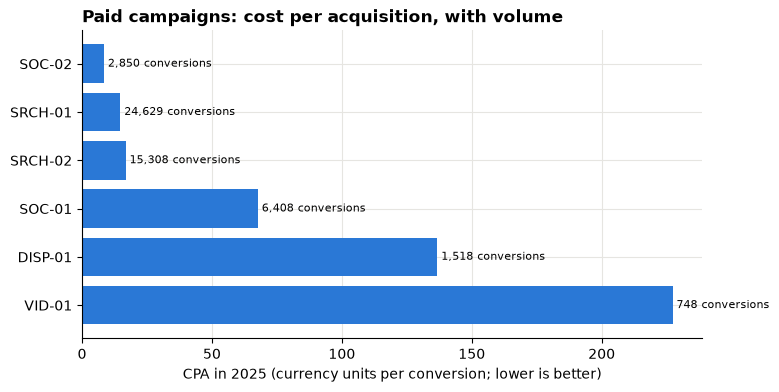

In [12]:
paid = scorecard.drop("Email", level="channel").reset_index().sort_values("CPA")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(paid["campaign_id"], paid["CPA"], color="#2a78d6")
ax.invert_yaxis()
for bar, conv in zip(bars, paid["conversions"]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f" {conv:,.0f} conversions",
            va="center", fontsize=8)
ax.set_title("Paid campaigns: cost per acquisition, with volume")
ax.set_xlabel("CPA in 2025 (currency units per conversion; lower is better)")
plt.show()

> **Check before you share**
>
> - [ ] Every rate is a ratio of sums, and the totals reconcile (G3).
> - [ ] Spend and conversions sit next to CPA and ROAS.
> - [ ] Email is flagged, not ranked first.
> - [ ] The title of your chart says what the reader should notice.

### I3 (Stretch): A monthly trend for one campaign

Is a campaign's efficiency stable through the year? Group one campaign's rows by **month**, sum, then add rates.

> **Your turn:** change the code in the next cell and run it again.

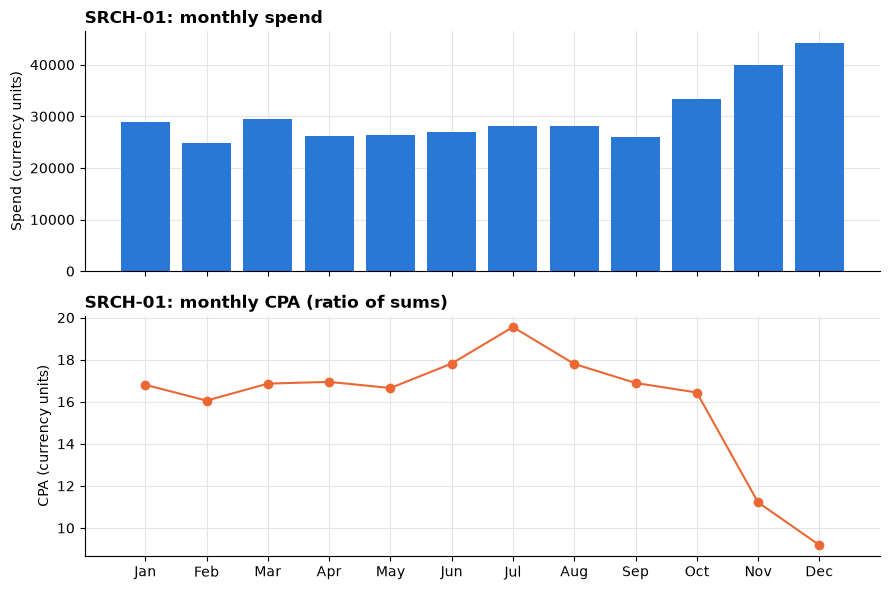

,spend,conversions,conv_rate,CPA,ROAS
date,,,,,
2025-01,"28,906.29","1,720",3.25%,16.81,7.11
2025-02,"24,820.25","1,546",3.37%,16.05,7.34
2025-03,"29,574.08","1,754",3.27%,16.86,7.04
2025-04,"26,264.18","1,550",3.17%,16.94,6.87
2025-05,"26,376.81","1,584",3.23%,16.65,6.94
2025-06,"26,970.11","1,514",3.14%,17.81,6.58
2025-07,"28,095.62","1,437",2.95%,19.55,5.88
2025-08,"28,118.80","1,580",3.14%,17.80,6.71
2025-09,"25,964.68","1,537",3.22%,16.89,7.08


In [13]:
# 1. Run the cell. In which months does spend rise? Does CPA rise or fall in those months?
# 2. Change campaign to "SOC-01", then "VID-01". Is the pattern the same?
# 3. Could you tell from this chart whether the extra spend CAUSED the change in CPA? Why not?
campaign = "SRCH-01"

one = daily[daily["campaign_id"] == campaign]
monthly = add_rates(one.groupby(one["date"].dt.to_period("M"))[COUNTS].sum())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
months = monthly.index.strftime("%b")
ax1.bar(months, monthly["spend"], color="#2a78d6")
ax1.set_title(f"{campaign}: monthly spend")
ax1.set_ylabel("Spend (currency units)")
ax2.plot(months, monthly["CPA"], marker="o", color="#eb6834", label="CPA")
ax2.set_title(f"{campaign}: monthly CPA (ratio of sums)")
ax2.set_ylabel("CPA (currency units)")
fig.tight_layout()
plt.show()
show(monthly[["spend", "conversions", "conv_rate", "CPA", "ROAS"]])

> **Hint**
>
> Two things changed at the end of the year: the budget and the shoppers. The monthly chart cannot separate them.

### I4 (Stretch): Do extra units of spend buy as much? A spend-band view

Split one campaign's days into four **spend bands** (quarters of its days, from the lowest-spend days to the highest), add up each band, and compare. This shows an **association** only: high-spend days may differ from low-spend days in other ways.

> **Your turn:** change the code in the next cell and run it again.

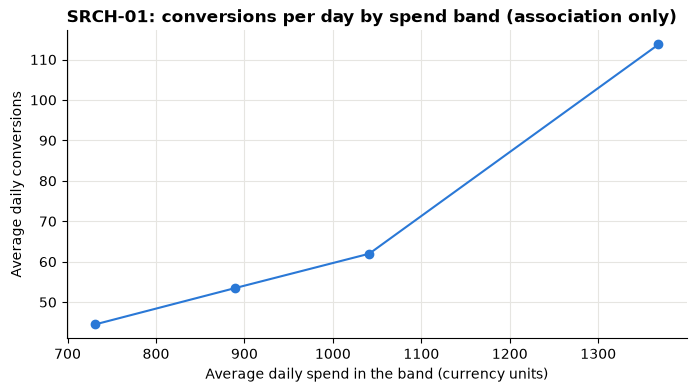

,days,spend per day,conversions per day,"cost per 1,000 impressions",CPA,share of days in Oct-Dec
spend band,,,,,,
lowest,90,730.82,44.48,21.34,16.43,1%
second,90,889.54,53.49,21.98,16.63,7%
third,90,"1,041.06",61.98,22.48,16.80,21%
highest,90,"1,368.08",113.71,23.46,12.03,71%


In [14]:
# 1. Run the cell. Does CPA rise or fall from the lowest to the highest spend band? And the cost per 1,000 impressions?
# 2. Look at "share of days in Oct-Dec". Why might the highest band look cheap per conversion?
# 3. Change months to range(1, 10) (January to September only) and run again. What changes, and why?
campaign = "SRCH-01"
months = range(1, 13)

rows = daily[(daily["campaign_id"] == campaign) & (daily["spend"] > 0) & daily["date"].dt.month.isin(months)].copy()
rows["spend band"] = pd.qcut(rows["spend"], 4, labels=["lowest", "second", "third", "highest"])
rows["in Oct-Dec"] = rows["date"].dt.month >= 10

bands = add_rates(rows.groupby("spend band", observed=True)[COUNTS].sum())
bands["days"] = rows.groupby("spend band", observed=True).size()
bands["share of days in Oct-Dec"] = rows.groupby("spend band", observed=True)["in Oct-Dec"].mean()
bands["cost per 1,000 impressions"] = safe_div(bands["spend"], bands["impressions"]) * 1000
bands["spend per day"] = bands["spend"] / bands["days"]
bands["conversions per day"] = bands["conversions"] / bands["days"]

ax = bands.plot(x="spend per day", y="conversions per day", marker="o", legend=False)
ax.set_title(f"{campaign}: conversions per day by spend band (association only)")
ax.set_xlabel("Average daily spend in the band (currency units)")
ax.set_ylabel("Average daily conversions")
plt.show()
(bands[["days", "spend per day", "conversions per day", "cost per 1,000 impressions", "CPA", "share of days in Oct-Dec"]]
 .round(2).assign(**{"share of days in Oct-Dec": bands["share of days in Oct-Dec"].map("{:.0%}".format)}))

> **Diminishing returns**
>
> Media usually gets more expensive per person reached as a campaign spends more: the cheapest audiences are reached first. If that is happening, each extra unit of spend buys fewer impressions and conversions than the last. Check the "cost per 1,000 impressions" column for this, and remember that the season can hide or exaggerate it.

---

## Challenge

### C1 (Challenge): Three broken ROAS analyses

A colleague sent three analyses. Each runs without an error. Each is wrong.

**Bug 1: averaged daily ROAS.** The colleague computes ROAS for every day with spend, then averages the days.

In [15]:
# Colleague's code (bug 1): do not copy this pattern.
paid_days = daily[daily["spend"] > 0].copy()
paid_days["daily_roas"] = paid_days["attributed_revenue"] / paid_days["spend"]
averaged = paid_days.groupby("campaign_id")["daily_roas"].mean()
averaged.round(2)

campaign_id
DISP-01    0.61
EML-01    27.37
SOC-01     1.32
SOC-02    12.69
SRCH-01    7.72
SRCH-02    5.97
VID-01     0.37
Name: daily_roas, dtype: float64

**Bug 2: ROAS on every row, including zero-spend days.** The same idea, but without removing the days with no spend.

In [16]:
# Colleague's code (bug 2): do not copy this pattern.
all_days = daily.copy()
all_days["daily_roas"] = all_days["attributed_revenue"] / all_days["spend"]
print("Rows with infinite ROAS:", np.isinf(all_days["daily_roas"]).sum())
print("Rows with NaN ROAS:     ", all_days["daily_roas"].isna().sum())
all_days.groupby("campaign_id")["daily_roas"].mean().round(2)

Rows with infinite ROAS: 12
Rows with NaN ROAS:      27


campaign_id
DISP-01    0.61
EML-01      inf
SOC-01     1.32
SOC-02    12.69
SRCH-01    7.72
SRCH-02    5.97
VID-01     0.37
Name: daily_roas, dtype: float64

> **Your turn:** change the code in the next cell and run it again.

In [17]:
# 1. Run the cell. Which campaigns differ between the averaged daily ROAS and the ratio of sums? By how much?
# 2. Why does bug 2 give "inf" for one campaign? Which rows cause it, and what are they called?
# 3. Write the correct ROAS calculation in one line, and one sentence explaining why averaging days is wrong
#    (hint: is a day with spend 50 as important as a day with spend 2,000?).
fixed = by_campaign["ROAS"].droplevel("channel")

check = pd.DataFrame({
    "bug 1: mean of daily ROAS": averaged,
    "bug 2: mean incl. zero-spend days": all_days.groupby("campaign_id")["daily_roas"].mean(),
    "correct: sum of revenue ÷ sum of spend": fixed,
})
check["bug 1 minus correct"] = check["bug 1: mean of daily ROAS"] - check["correct: sum of revenue ÷ sum of spend"]
check.round(2)

,bug 1: mean of daily ROAS,bug 2: mean incl. zero-spend days,correct: sum of revenue ÷ sum of spend,bug 1 minus correct
campaign_id,,,,
DISP-01,0.61,0.61,0.64,-0.02
EML-01,27.37,inf,29.25,-1.88
SOC-01,1.32,1.32,1.37,-0.05
SOC-02,12.69,12.69,13.15,-0.46
SRCH-01,7.72,7.72,7.99,-0.27
SRCH-02,5.97,5.97,6.19,-0.22
VID-01,0.37,0.37,0.40,-0.03


**Bug 3: "attributed means incremental".** The colleague's message to the marketing lead:

> *"Attributed revenue is the revenue our campaigns bring in. The highest-ROAS paid campaign returns many times what it costs, so let's move the whole budget into it next quarter. Revenue will go up by its ROAS times the extra spend."*

Answer in your evidence log:

1. What does "attributed" mean in this table? Would all of that revenue disappear if the campaign stopped?
2. Which campaign is the highest-ROAS **paid** campaign? Look at its **audience** (campaign name) and its **size**. Why might its ROAS overstate what extra money would earn?
3. Use your I4 results: if a campaign's spend rose several times over, would its ROAS stay the same?
4. The colleague's sentence "revenue will go up by its ROAS times the extra spend" assumes three things. Name them.

> **Hint**
>
> Think about (a) buyers who would have bought anyway, (b) diminishing returns as a campaign spends more, (c) what happens to the conversions of the campaigns whose budget is cut, and (d) ROAS is before product cost and returns.

### C2 (Challenge): Write the test proposal

Turn your findings into **one** controlled test the lead can approve. First, get a feel for how noisy a candidate campaign's weekly results are, outside the end-of-year season. A test has to run long enough for a real effect to stand out from this week-to-week wobble.

> **Your turn:** change the code in the next cell and run it again.

SRCH-02: 38 complete weeks, January to September
Weekly conversions: mean 228, standard deviation 21
Weekly spend:       mean 4,482


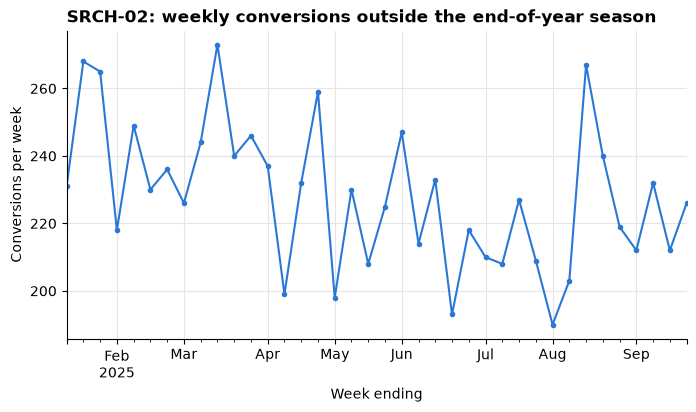

In [18]:
# 1. Set candidate to the campaign you would test. Run the cell.
# 2. How much do weekly conversions vary from week to week (compare the standard deviation with the mean)?
# 3. If the budget change might add a tenth more conversions, would a two-week test show it clearly? What about eight weeks?
candidate = "SRCH-02"

one = daily[daily["campaign_id"] == candidate].set_index("date")
weekly = one.resample("W-SUN")[["spend", "conversions"]].sum().loc["2025-01-12":"2025-09-28"]   # complete weeks, Jan-Sep

print(f"{candidate}: {len(weekly)} complete weeks, January to September")
print(f"Weekly conversions: mean {weekly['conversions'].mean():,.0f}, standard deviation {weekly['conversions'].std():,.0f}")
print(f"Weekly spend:       mean {weekly['spend'].mean():,.0f}")

ax = weekly["conversions"].plot(marker="o", markersize=3)
ax.set_title(f"{candidate}: weekly conversions outside the end-of-year season")
ax.set_xlabel("Week ending")
ax.set_ylabel("Conversions per week")
plt.show()

Now write the proposal in your evidence log. Keep it to one short paragraph per heading.

| Heading | What to write |
|---|---|
| **Candidate and why** | The campaign, with its scorecard numbers (spend, conversions, CPA, ROAS) and why it is worth testing |
| **Change** | Exactly what changes, for example the daily budget by a set share |
| **Design** | Holdout, geo split or time switching; what is randomised; what the control group gets |
| **Primary metric** | One number, decided now: total conversions (or revenue) in the test group compared with control, **not** attributed revenue |
| **Guardrails** | What must not get worse: for example CPA, conversions of the other campaigns, return rate |
| **Duration** | Whole weeks, long enough given the weekly noise above; avoid or plan around the end-of-year season |
| **Decision rule** | What result means scale up, keep or stop, using a 95% interval as in Session 9 |
| **Limits** | What the test still cannot tell you: product cost, returns, long-term effects |

> **Avoid these phrases**
>
> "Attributed revenue proves the campaign works." "ROAS of 8 means 8 times profit." "Move everything into the best campaign." "Social converts better than Search" (from the mean of rates).

---

## Validation checklist

- [ ] The key (`date`, `campaign_id`) is unique and complete; every row respects the funnel order.
- [ ] Every rate at every level is a **ratio of sums**; none is an average or sum of rates.
- [ ] Campaign and channel totals reconcile to the company total.
- [ ] Zero denominators show as "not available", never 0 or infinity; review cases are listed, not deleted.
- [ ] Channel rates are weighted, and the volumes are visible.
- [ ] Email's ROAS is flagged as not comparable.
- [ ] No sentence calls attributed revenue incremental, or ROAS profit.
- [ ] The recommendation is a **test**, with one primary metric, guardrails, a duration and a decision rule.

---

## Exit ticket

1. Why must a channel's conversion rate be total conversions ÷ total sessions, not the average of its campaigns' rates?
2. A campaign spent nothing on a day but had five conversions. What do you report for its ROAS that day, and what do you do with the row?
3. Give one reason Email's ROAS is not comparable with Search's.
4. What is the difference between **attributed** revenue and **incremental** revenue?
5. Name the primary metric and one guardrail for your proposed test.

---

## Evidence to keep

- [ ] Your campaign scorecard with volumes and flags (I2), and the reconciliation check (G3)
- [ ] Your explanation of the weighted rate versus the mean of campaign rates (I1)
- [ ] Your test proposal (C2)
- [ ] Optional: the monthly trend or spend-band view (I3–I4) and your answers to the three bugs (C1)